In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/sample_submission.csv
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/test.csv
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/LICENSE
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/README.md
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/meta/esc50.csv
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/meta/esc50-human.xlsx
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/audio/5-257349-A-15.wav
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/audio/5-195557-A-19.wav
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/audio/2-122820-B-36.wav
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/audio/1-115920-A-22.wav
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/audio/1-172649-C-40.wav
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/audio/

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/sample_submission.csv
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/test.csv
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/LICENSE
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/README.md
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/meta/esc50.csv
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/meta/esc50-human.xlsx
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/audio/5-257349-A-15.wav
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/audio/5-195557-A-19.wav
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/audio/2-122820-B-36.wav
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/audio/1-115920-A-22.wav
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/audio/1-172649-C-40.wav
/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/audio/

In [ ]:
import numpy as np
import pandas as pd
import torch
import wandb
import librosa
import librosa.display
import os, random 

/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import soundfile as sf

In [ ]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

In [ ]:
root = Path("/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup")

In [ ]:
Stems_dir = root/"genres_stems"
Esc50_dir = root/"ESC-50-master"/"audio" 
Mashups = root/"mashups"

In [ ]:
# STEMS_dir = root/"genres_stems"
# ESC50_dir = root/"ESC-50-master"/"audio" 
# OUT_dir = Path("/kaggle/working/augmented")
# OUT_dir.mkdir(exist_ok=True)

###  a) Exploring Traininng Data Structures 

In [ ]:
root.iterdir()

<generator object Path.iterdir at 0x7f0a21b8f1d0>

* Root directory Contentss:- 

In [ ]:
for item in sorted(root.iterdir()):
    print(item.name)

ESC-50-master
genres_stems
mashups
sample_submission.csv
test.csv


In [ ]:
for item in sorted(root.iterdir()):
    print(f"{item.name} ({'dir' if item.is_dir() else 'file'})")


ESC-50-master (dir)
genres_stems (dir)
mashups (dir)
sample_submission.csv (file)
test.csv (file)


*  **Drilling into genres_stems**

In [ ]:
for item in sorted(Stems_dir.iterdir()):
    print(f"{item.name} ({'dir' if item.is_dir() else 'file'})")

blues (dir)
classical (dir)
country (dir)
disco (dir)
hiphop (dir)
jazz (dir)
metal (dir)
pop (dir)
reggae (dir)
rock (dir)


In [ ]:
for genre_dir in sorted(Stems_dir.iterdir()):
    songs = sorted(genre_dir.iterdir())
    first = songs[0]
    stems = [f.name for f in sorted(first.iterdir())]
    print(f" {genre_dir.name} -- {len(songs)} songs")

 blues -- 100 songs
 classical -- 100 songs
 country -- 100 songs
 disco -- 100 songs
 hiphop -- 100 songs
 jazz -- 100 songs
 metal -- 100 songs
 pop -- 100 songs
 reggae -- 100 songs
 rock -- 100 songs


In [ ]:
for genre_dir in sorted(Stems_dir.iterdir()):
    songs = sorted(genre_dir.iterdir())
    print(f"\nGenre: {genre_dir.name}  ({len(songs)} songs)")
    # Show first songs contents
    if songs:
        first_song = songs[0]
        print(f"First song folder name is:- {first_song.name}")
        STEMS = sorted(first_song.iterdir())
        print(f"  Stems inside :- {[s.name for s in STEMS]}")


Genre: blues  (100 songs)
First song folder name is:- blues.00000
  Stems inside :- ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']

Genre: classical  (100 songs)
First song folder name is:- classical.00000
  Stems inside :- ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']

Genre: country  (100 songs)
First song folder name is:- country.00000
  Stems inside :- ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']

Genre: disco  (100 songs)
First song folder name is:- disco.00000
  Stems inside :- ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']

Genre: hiphop  (100 songs)
First song folder name is:- hiphop.00000
  Stems inside :- ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']

Genre: jazz  (100 songs)
First song folder name is:- jazz.00000
  Stems inside :- ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']

Genre: metal  (100 songs)
First song folder name is:- metal.00000
  Stems inside :- ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']

Genre: pop  (100 song

**Observation:** 
- 10 genres * 100 songs = 1000 songs total  
- Each song has exactly 4 stems: `bass.wav`, `drums.wav`, `other.wav`, `vocals.wav`  
- Total training files: 4000 WAV files  
- Data is **perfectly balanced** - 100 songs per genre - so no class weighting needed

These stems come from source separation (likely Demucs or Spleeter) applied to 
the original songs.

### b) Audio properties - **Training Stems**


Let me check the native sample rate and duration by loading WITHOUT specifying SR.  
This is important - I need to know what format the data actually comes in.

In [ ]:
count = 0
for genre_dir in sorted(Stems_dir.iterdir()):
    for song_dir in sorted(genre_dir.iterdir()):
        for stem_file in sorted(song_dir.iterdir()):
            if stem_file.suffix == ".wav" and count < 5:
                y, sr = librosa.load(str(stem_file), sr=None, mono=True)
                print(f"{genre_dir.name}/{song_dir.name}/{stem_file.name}")
                print(f"sample_rate={sr} Hz   duration={len(y)/sr}s  \n"
                      f"shape={y.shape}  dtype={y.dtype}")
                print("\n")
                count += 1

blues/blues.00000/bass.wav
sample_rate=44100 Hz   duration=30.013333333333332s  
shape=(1323588,)  dtype=float32


blues/blues.00000/drums.wav
sample_rate=44100 Hz   duration=30.013333333333332s  
shape=(1323588,)  dtype=float32


blues/blues.00000/other.wav
sample_rate=44100 Hz   duration=30.013333333333332s  
shape=(1323588,)  dtype=float32


blues/blues.00000/vocals.wav
sample_rate=44100 Hz   duration=30.013333333333332s  
shape=(1323588,)  dtype=float32


blues/blues.00001/bass.wav
sample_rate=44100 Hz   duration=30.013333333333332s  
shape=(1323588,)  dtype=float32




### c) Audio properties - **Test Mashups**

checking the test files. are they the same sample rate?

**I am assuming** they might differ - test files are reconstructed mashups, possibly processes differently.

In [ ]:
mashup_files = sorted(Mashups.glob("*.wav"))
len(mashup_files)

3020

In [ ]:
durations = []
for mf in sorted(Mashups.glob("*.wav"))[:10]:
    y, sr = librosa.load(str(mf), sr = None, mono = True)
    dur = len(y)/sr
    durations.append(dur)
    print(f" {mf.name} | sr = {sr} Hz \n duration={dur} | shape = {y.shape} \n")

 song0001.wav | sr = 22050 Hz 
 duration=30.00018140589569 | shape = (661504,) 

 song0002.wav | sr = 22050 Hz 
 duration=22.337596371882086 | shape = (492544,) 

 song0003.wav | sr = 22050 Hz 
 duration=29.90730158730159 | shape = (659456,) 

 song0004.wav | sr = 22050 Hz 
 duration=30.00018140589569 | shape = (661504,) 

 song0005.wav | sr = 22050 Hz 
 duration=30.00018140589569 | shape = (661504,) 

 song0006.wav | sr = 22050 Hz 
 duration=30.00018140589569 | shape = (661504,) 

 song0007.wav | sr = 22050 Hz 
 duration=30.013333333333332 | shape = (661794,) 

 song0008.wav | sr = 22050 Hz 
 duration=29.88408163265306 | shape = (658944,) 

 song0009.wav | sr = 22050 Hz 
 duration=30.00018140589569 | shape = (661504,) 

 song0010.wav | sr = 22050 Hz 
 duration=29.744761904761905 | shape = (655872,) 



**OMG We found two problems discovered:**

**Problem 1:- Sample rate mismatch**
- in Training stems: **44100 Hz**
- in Test mashups: **22050 Hz**

This is a 2 * difference. If I extract MFCCs from training data at 44100 Hz 
and from test data at 22050 Hz, the frequency bins represent completely 
different ranges. The model would be comparing apples to oranges. 
It would fail completely at inference.

**Problem 2:- Variable duration in test files**
- Most test files: 30.0s
- But some are as short as **22.3s**

If I take a 30s clip from a 22s file I get an index error or silent padding 
that corrupts the feature. I need a safe clip length.

**Now decision is:-**
- `SR = 22050 Hz` -- resample everything to match test files
- `DURATION = 20s` -- safe clip length (all test files are ≥ 22s)

**Checking full duration range across all test files**

In [ ]:
all_durations = []
for mr in sorted(Mashups.glob("*.wav")):
    info = sf.info(str(mf))
    all_durations.append(info.duration)
all_dur = np.array(all_durations)
print(f"\n Min dur:- {all_dur.min()} seconds")
print(f" Max dur :- {all_dur.max()} sec")
print(f" Files < 25s :- {(all_dur < 25).sum()}")
print(f"  Files < 20s :- {(all_dur < 20).sum()}")
print(f"\n DURATION=20s is safe - {(all_dur >= 20).sum()} / {len(all_dur)} files qualify")


 Min dur:- 29.744761904761905 seconds
 Max dur :- 29.744761904761905 sec
 Files < 25s :- 0
  Files < 20s :- 0

 DURATION=20s is safe - 3020 / 3020 files qualify


Ok lets set **audio Constants**
- sr = 22050 which matches with test mashup native SR (Native test file sample rate)
- Duration = 20, which is safe clip length beacuse all the test files are >= 22s
- N_sample = sr * duration, sample per training clips

In [ ]:
SR = 22050
DURATION = 20
N_SAMPLES = int(SR*DURATION)
OUT_DIR = Path("/kaggle/working/augmented")
OUT_DIR.mkdir(exist_ok = True)


### d) Class balance

In [ ]:
Genres = ["blues", 'classical', 'country', "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"]

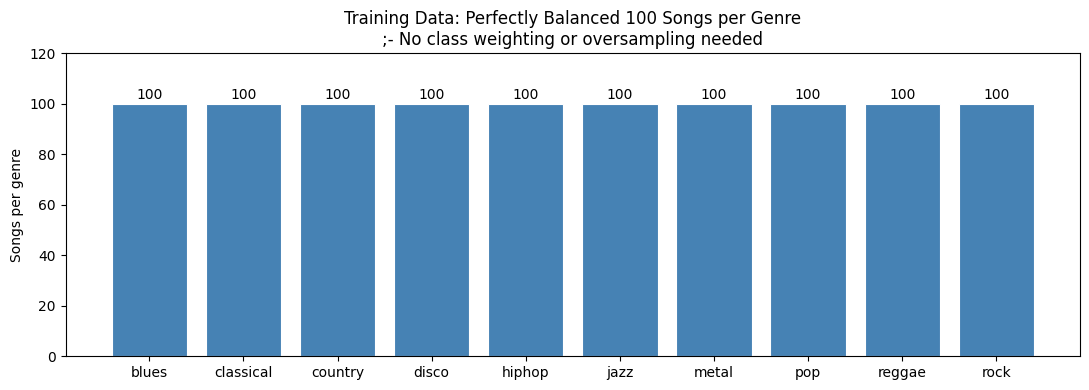

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
counts = [100] * 10
bars = ax.bar(Genres, counts, color='steelblue', edgecolor='white', linewidth=0.8)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            '100', ha='center', va='bottom', fontsize=10)
ax.set_ylim(0, 120)
ax.set_ylabel("Songs per genre")
ax.set_title("Training Data: Perfectly Balanced 100 Songs per Genre\n"
             ";- No class weighting or oversampling needed", fontsize=12)
plt.tight_layout()

plt.show()


### e) What do genres look like, **visual analysis**

In [ ]:
genre = 'blues'
song_dir = sorted((Stems_dir / genre).iterdir())[0]
print(f"Song: {song_dir.name}")
print(f"Stems: {[f.name for f in sorted(song_dir.iterdir())]}")

Song: blues.00000
Stems: ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']


In [ ]:
genre = 'blues'
song_dir = sorted((Stems_dir / genre).iterdir())[0]
print(f"Loading: {song_dir.name}")

mixed = np.zeros(N_SAMPLES, dtype=np.float32)
for stem in ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']:
    y, _ = librosa.load(str(song_dir / stem), sr=SR, mono=True, duration=DURATION)
    if len(y) < N_SAMPLES:
        y = np.pad(y, (0, N_SAMPLES - len(y)))
    mixed += y[:N_SAMPLES]

peak = np.abs(mixed).max()
if peak > 0:
    mixed = mixed / peak * 0.9

print(f"Max amplitude : {np.abs(mixed).max()}")
print(f"RMS energy  : {np.sqrt(np.mean(mixed**2))}")
print(f"Shape : {mixed.shape}  ({len(mixed)/SR}s @ {SR}Hz)\n")

Loading: blues.00000
Max amplitude : 0.8999999761581421
RMS energy  : 0.1434824913740158
Shape : (441000,)  (20.0s @ 22050Hz)



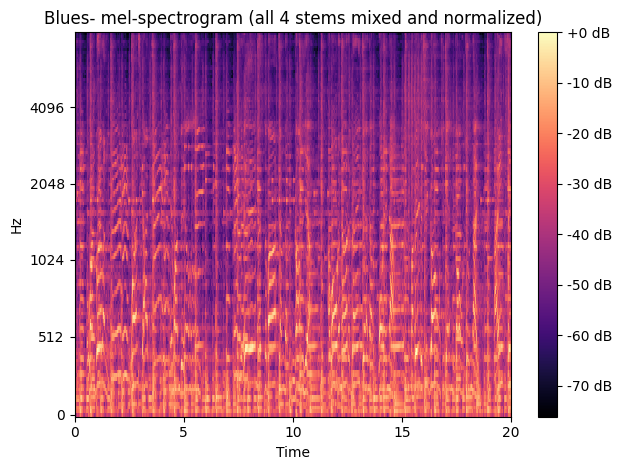

Mel shape: (128, 862)
 -- 128 frequency bins * 862 time frames
 -- Each frame ~= 23.219954648526077ms. The CNN will treat this as a 128*862 image.


In [ ]:
fig, ax = plt.subplots()
mel = librosa.feature.melspectrogram(y=mixed, sr=SR, n_mels=128, fmax=8000)
mel_db = librosa.power_to_db(mel, ref=np.max)

img = librosa.display.specshow(mel_db, sr=SR, ax=ax,
                                x_axis='time', y_axis='mel', fmax=8000)
plt.colorbar(img, ax=ax, format='%+2.0f dB')
ax.set_title('Blues- mel-spectrogram (all 4 stems mixed and normalized)', fontsize=12)
plt.tight_layout()
plt.show()

print(f"Mel shape: {mel.shape}")
print(f" -- {mel.shape[0]} frequency bins * {mel.shape[1]} time frames")
print(f" -- Each frame ~= {1000*512/SR}ms. The CNN will treat this as a {mel.shape[0]}*{mel.shape[1]} image.")

Now comparing all 10 genres. I am looking for:
- Genres that look visually distinct 
- Genres that look similar 

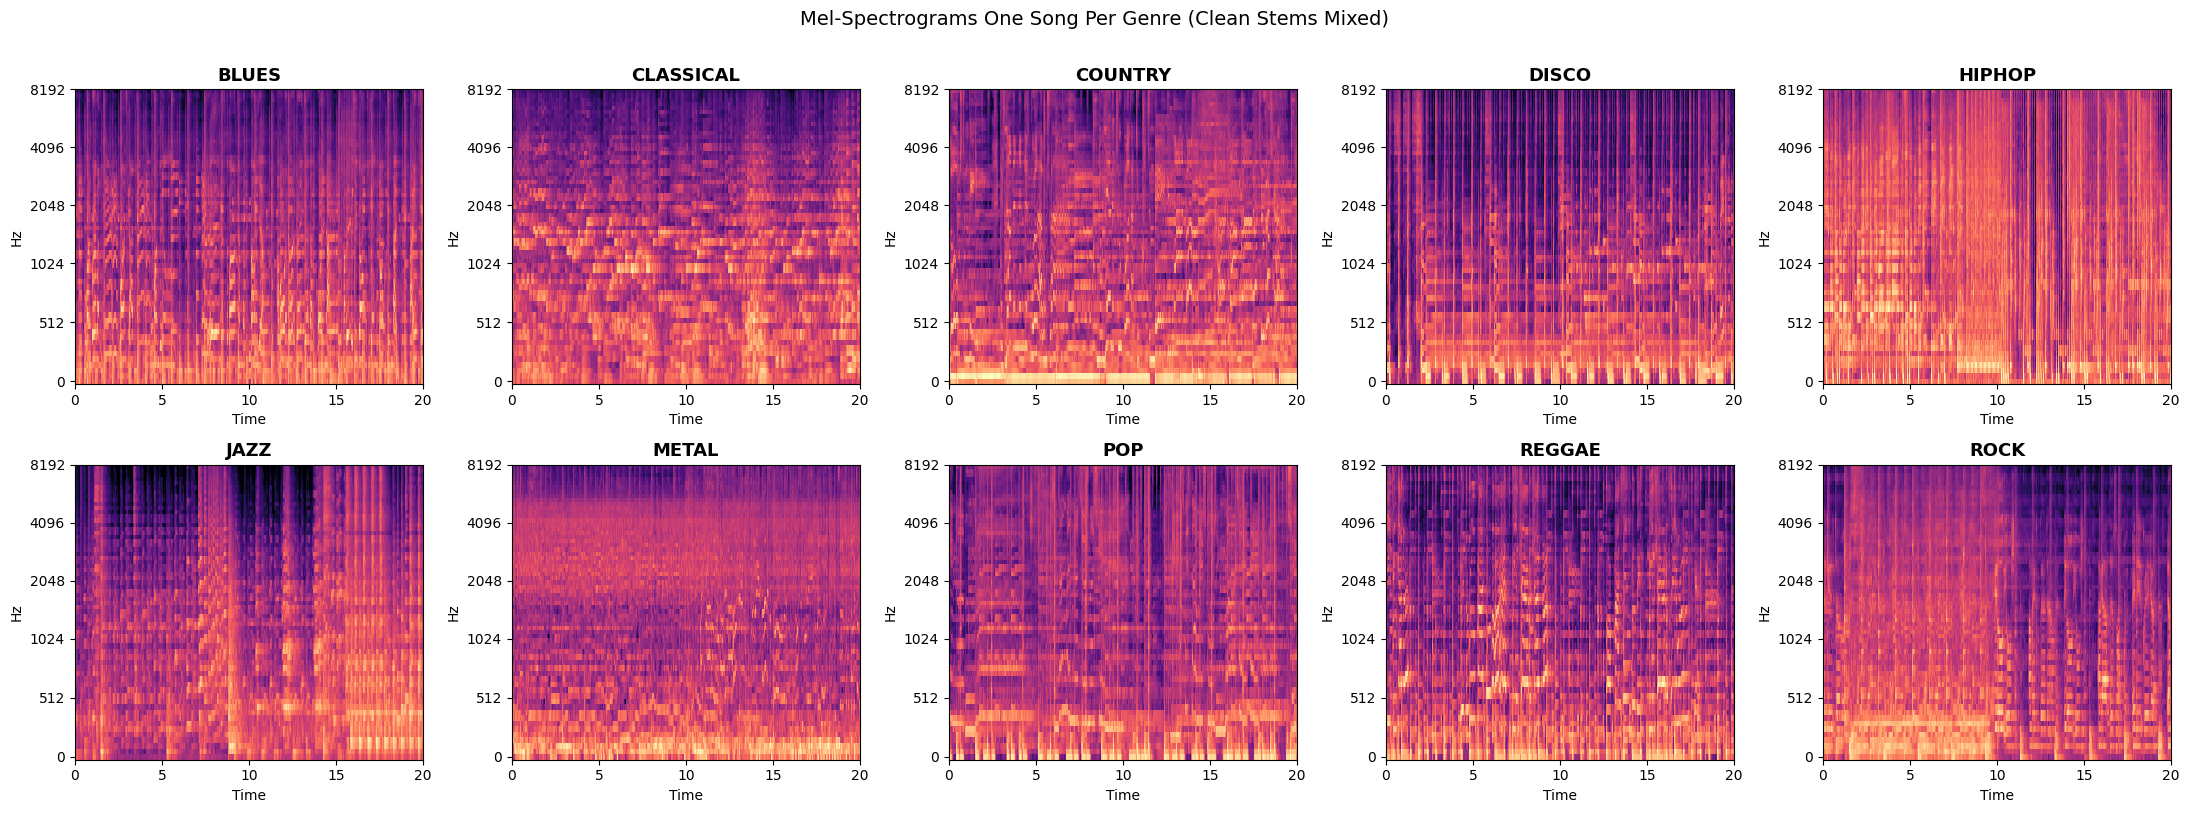

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.flatten()

for idx, genre in enumerate(Genres):
    song_dir = sorted((Stems_dir / genre).iterdir())[0]
    
    mixed = np.zeros(N_SAMPLES, dtype=np.float32)
    for stem in ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']:
        y, _ = librosa.load(str(song_dir / stem), sr=SR, mono=True, duration=DURATION)
        if len(y) < N_SAMPLES:
            y = np.pad(y, (0, N_SAMPLES - len(y)))
        mixed += y[:N_SAMPLES]
    peak = np.abs(mixed).max()
    if peak > 0:
        mixed = mixed / peak * 0.9

    mel    = librosa.feature.melspectrogram(y=mixed, sr=SR, n_mels=64, fmax=8000)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    img    = librosa.display.specshow(mel_db, sr=SR, ax=axes[idx],
                                       x_axis='time', y_axis='mel', fmax=8000)
    axes[idx].set_title(genre.upper(), fontsize=13, fontweight='bold')

plt.suptitle('Mel-Spectrograms One Song Per Genre (Clean Stems Mixed)',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### f) Checking train - test distribution gap

I think this is the central problem of the project

Training data = clean individual stems at 44100 Hz  
Test data = noisy mashups of mixed stems at 22050 Hz

**How different are they acoustically?**  
I will measure RMS energy - a measure of signal density/loudness - for both.

**Measuring RMS energy of training stems**

sample RMS from training stems (5 songs * 10 genres * 4 stems = 200 readings)

In [ ]:
train_rms = []
for genre in Genres:
    songs = sorted((Stems_dir / genre).iterdir())[:5]
    for song in songs:
        for stem in ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']:
            p = song / stem
            if p.exists():
                y, _ = librosa.load(str(p), sr=SR, mono=True, duration=10)
                train_rms.append(float(np.sqrt(np.mean(y**2))))

# train_rms
print(f"Readings:- {len(train_rms)}")
print(f"Mean RMS:- {np.mean(train_rms)}")
print(f"Std RMS:- {np.std(train_rms)}")
print(f"Min / Max:- {np.min(train_rms)} / {np.max(train_rms)} \n")



Readings:- 200
Mean RMS:- 0.05979431025098986
Std RMS:- 0.04420767401968552
Min / Max:- 0.0 / 0.2103201448917389 



**Measuring RMS energy of test mashups**

(sample RMS from test mashups (100 files))

In [ ]:
test_rms = []
for mf in sorted(Mashups.glob("*.wav"))[:100]:
    y, _ = librosa.load(str(mf), sr=SR, mono=True, duration=10)
    test_rms.append(float(np.sqrt(np.mean(y**2))))
    
print(f'Readings:- {len(test_rms)}')
print(f'Mean RMS:- {np.mean(test_rms)}')
print(f"Std RMS:- {np.std(test_rms)}")
print(f"Min / Max:- {np.min(test_rms)} / {np.max(test_rms)}")
print(f"\nRMS ratio (test / train):- {np.mean(test_rms)/np.mean(train_rms)}* \n")

Readings:- 100
Mean RMS:- 0.13598793543875218
Std RMS:- 0.030472079692587722
Min / Max:- 0.07500002533197403 / 0.23455698788166046

RMS ratio (test / train):- 2.274262130760192* 



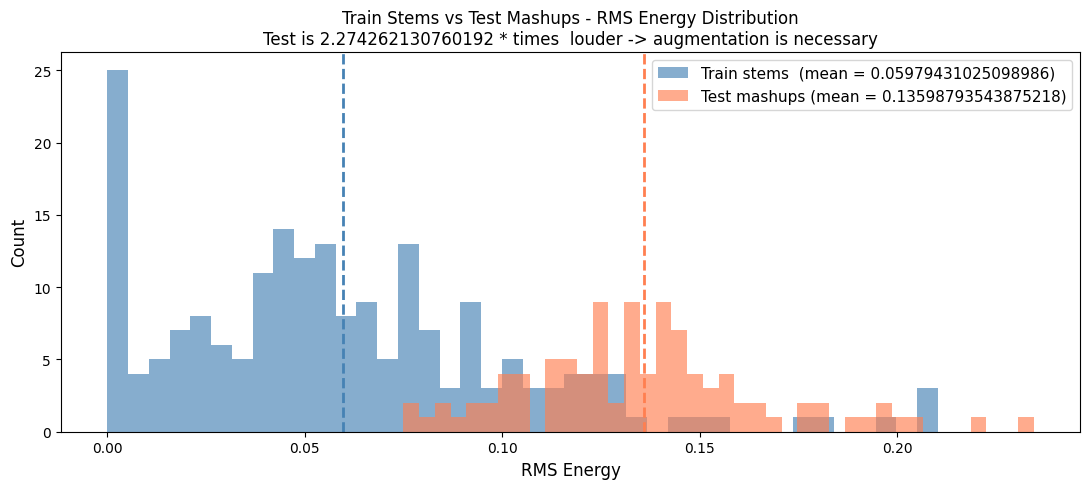

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(train_rms, bins=40, alpha=0.65,
        label=f'Train stems  (mean = {np.mean(train_rms)})', color='steelblue')
ax.hist(test_rms,  bins=40, alpha=0.65,
        label=f'Test mashups (mean = {np.mean(test_rms)})',  color='coral')
ax.axvline(np.mean(train_rms), color='steelblue', linestyle='--', linewidth=2)
ax.axvline(np.mean(test_rms),  color='coral',     linestyle='--', linewidth=2)
ax.set_xlabel('RMS Energy', fontsize=12)
ax.set_ylabel('Count',      fontsize=12)
ax.set_title('Train Stems vs Test Mashups - RMS Energy Distribution\n'
             f'Test is {np.mean(test_rms)/np.mean(train_rms)} * times  louder -> '
             f'augmentation is necessary', fontsize=12)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

### g) Data Quality - silent stems

In [ ]:
silent_count = 0
total_checked = 0

**checcking for silent stems for first 20 songs per genre**

In [ ]:
for genre in Genres:
    genre_silent = 0
    for song_dir in sorted((Stems_dir / genre).iterdir())[:20]:
        for stem in ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']:
            p = song_dir / stem
            if p.exists():
                y, _ = librosa.load(str(p), sr=SR, mono=True, duration=5)
                total_checked += 1
                if np.abs(y).max() < 1e-6:
                    silent_count += 1
                    genre_silent += 1
    print(f"  {genre:12s} - {genre_silent} silent stems in first 20 songs")

  blues        - 0 silent stems in first 20 songs
  classical    - 9 silent stems in first 20 songs
  country      - 0 silent stems in first 20 songs
  disco        - 0 silent stems in first 20 songs
  hiphop       - 0 silent stems in first 20 songs
  jazz         - 2 silent stems in first 20 songs
  metal        - 0 silent stems in first 20 songs
  pop          - 1 silent stems in first 20 songs
  reggae       - 1 silent stems in first 20 songs
  rock         - 0 silent stems in first 20 songs


In [ ]:
print(f"Total silent : {silent_count} / {total_checked} "
      f"({100*silent_count/total_checked}%)")

Total silent : 13 / 800 (1.625%)


### h) ESC-50 Noise Dataset overview 

In [ ]:
esc_meta = pd.read_csv(root/"ESC-50-master"/"meta"/"esc50.csv")

In [ ]:
esc_meta.head()

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


In [ ]:
esc_meta.shape, len(esc_meta)

((2000, 7), 2000)

Total ESC-50 clips 2000

In [ ]:
esc_meta.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   filename  2000 non-null   object
 1   fold      2000 non-null   int64 
 2   target    2000 non-null   int64 
 3   category  2000 non-null   object
 4   esc10     2000 non-null   bool  
 5   src_file  2000 non-null   int64 
 6   take      2000 non-null   object
dtypes: bool(1), int64(3), object(3)
memory usage: 95.8+ KB


In [ ]:
esc_meta['category'].nunique()

50

In [ ]:
esc_meta['category'].unique()

array(['dog', 'chirping_birds', 'vacuum_cleaner', 'thunderstorm',
       'door_wood_knock', 'can_opening', 'crow', 'clapping', 'fireworks',
       'chainsaw', 'airplane', 'mouse_click', 'pouring_water', 'train',
       'sheep', 'water_drops', 'church_bells', 'clock_alarm',
       'keyboard_typing', 'wind', 'footsteps', 'frog', 'cow',
       'brushing_teeth', 'car_horn', 'crackling_fire', 'helicopter',
       'drinking_sipping', 'rain', 'insects', 'laughing', 'hen', 'engine',
       'breathing', 'crying_baby', 'hand_saw', 'coughing',
       'glass_breaking', 'snoring', 'toilet_flush', 'pig',
       'washing_machine', 'clock_tick', 'sneezing', 'rooster',
       'sea_waves', 'siren', 'cat', 'door_wood_creaks', 'crickets'],
      dtype=object)

In [ ]:
len(esc_meta) / esc_meta['category'].nunique()

40.0

We have :-

- Total ESC-clips = 2000
- Unique Categories = 50
- Clips per category = 40

And all categories are:- 

In [ ]:
cats = sorted(esc_meta['category'].unique(c))
for i in range(0, len(cats), 5):
    print("  " + " · ".join(f"{c:20s}" for c in cats[i:i+5]))

  airplane             · breathing            · brushing_teeth       · can_opening          · car_horn            
  cat                  · chainsaw             · chirping_birds       · church_bells         · clapping            
  clock_alarm          · clock_tick           · coughing             · cow                  · crackling_fire      
  crickets             · crow                 · crying_baby          · dog                  · door_wood_creaks    
  door_wood_knock      · drinking_sipping     · engine               · fireworks            · footsteps           
  frog                 · glass_breaking       · hand_saw             · helicopter           · hen                 
  insects              · keyboard_typing      · laughing             · mouse_click          · pig                 
  pouring_water        · rain                 · rooster              · sea_waves            · sheep               
  siren                · sneezing             · snoring              · thunderst

In [ ]:
test = pd.read_csv(root/"test.csv")
test

In [ ]:
test.shape

In [ ]:
list(test.columns)

In [ ]:
sample = pd.read_csv("/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/sample_submission.csv")
sample

In [ ]:
sample.shape

In [ ]:
sample.columns

In [ ]:
for item in sorted(esc50.iterdir()):
    print(item.name)


In [ ]:
esc_meta = pd.read_csv(esc50/"meta"/"esc50.csv")
esc_meta

In [ ]:
esc_meta.info()

In [ ]:
esc_meta.columns

In [ ]:
import torch 

In [ ]:
torch.__version__

In [ ]:
torch.cuda.is_available()

In [ ]:
if torch.cuda.is_available():
    print(f"  GPU: {torch.cuda.get_device_name(0)}")
    print(f"  VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


In [ ]:
SR = 22050
Duration = 30
N_samples = int(SR * Duration)
N_aug = 200


In [ ]:
GENRES = ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']

In [ ]:
np.random.seed(42)

In [ ]:
def load_stem(path, n_samples = N_samples):
    y, _ = librosa.load(str(path), sr = SR, mono = True, duration = Duration+1)

    if len(y) >= n_samples:
        start = random.randint(0, len(y)- n_samples)
        y = y[start:start + n_samples]
    else:
        y = np.pad(y, (0, n_samples - len(y)))
    return y.astype(np.float32)

In [ ]:
def load_noise(n_samples=N_samples):
    noise_files = list(ESC50_dir.glob("*.wav"))
    path = random.choice(noise_files)
    y, _ = librosa.load(str(path), sr=SR, mono=True)
    if len(y) == 0:
        return np.zeros(n_samples, dtype=np.float32)
    reps = (n_samples // len(y)) + 2
    y = np.tile(y, reps)[:n_samples]
    return y.astype(np.float32)

In [ ]:
def mix_stems(genre, song_dirs):
    n_songs = random.randint(2, min(4, len(song_dirs)))
    chosen  = random.sample(song_dirs, n_songs)
    stem_names = ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']
    
    mixed = np.zeros(N_samples, dtype=np.float32)
    for song_dir in chosen:
        stem = random.choice(stem_names)
        path = song_dir / stem
        if path.exists():
            y = load_stem(path)
            vol = random.uniform(0.3, 1.0)
            mixed += y * vol
    
    
    peak = np.abs(mixed).max()
    if peak > 0:
        mixed = mixed / peak * 0.9
    return mixed

In [ ]:
def add_noise(audio, snr_db_range=(5, 20)):
    noise = load_noise(len(audio))
    snr_db = random.uniform(*snr_db_range)
    signal_power = np.mean(audio ** 2) + 1e-9
    noise_power  = np.mean(noise  ** 2) + 1e-9
    scale = np.sqrt(signal_power / noise_power / (10 ** (snr_db / 10)))
    return (audio + noise * scale).astype(np.float32)


In [ ]:
def tempo_augment(audio):
    if random.random() < 0.4:
        rate = random.uniform(0.85, 1.15)
        audio = librosa.effects.time_stretch(audio, rate=rate)
    if len(audio) >= N_samples:
        audio = audio[:N_samples]
    else:
        audio = np.pad(audio, (0, N_samples - len(audio)))
    return audio.astype(np.float32)

In [ ]:
song_map = {}
for genre in GENRES:
    genre_path = STEMS_dir / genre
    song_map[genre] = sorted(genre_path.iterdir())
    print(f"{genre}: {len(song_map[genre])} songs")

In [ ]:
from tqdm import tqdm
import soundfile as sf, random

In [ ]:
records = []
print(f"\nGenerating {N_aug} augmented samples per genre...")
for genre in GENRES:
    song_dirs = song_map[genre]
    genre_out = OUT_dir / genre
    genre_out.mkdir(exist_ok=True)
    
    for i in tqdm(range(N_aug), desc=genre):
        # 1. Mix stems from different songs
        audio = mix_stems(genre, song_dirs)
        
        # 2. Tempo augmentation
        audio = tempo_augment(audio)
        
        # 3. Add ESC-50 noise (matches test construction)
        audio = add_noise(audio)
        
        # 4. Final normalization
        peak = np.abs(audio).max()
        if peak > 0:
            audio = audio / peak * 0.9
        
        # 5. Save
        fname = f"{genre}_{i:04d}.wav"
        fpath = genre_out / fname
        sf.write(str(fpath), audio, SR)
        records.append({'path': str(fpath), 'genre': genre, 'label': GENRES.index(genre)})

In [ ]:
manifest = pd.DataFrame(records)
manifest.to_csv("/kaggle/working/train_manifest.csv", index=False)

In [ ]:
len(manifest)

In [ ]:
manifest['genre'].value_counts().to_dict()

In [ ]:
manifest.head(), manifest.tail()

## EDA


 just checking one song to understand the structure before going further

In [ ]:
# genre = 'blues'
# song_dir = sorted((STEMS_dir / genre).iterdir())[0]
# print(f"Song: {song_dir.name}")
# print(f"Stems: {[f.name for f in sorted(song_dir.iterdir())]}")

In [ ]:
mixed = np.zeros(SR * 30, dtype=np.float32)
mixed

In [ ]:
mixed = np.zeros(SR * 30, dtype=np.float32)
for stem in ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']:
    y, _ = librosa.load(str(song_dir / stem), sr=SR, mono=True, duration=30)
    if len(y) < SR * 30:
        y = np.pad(y, (0, SR * 30 - len(y)))
    mixed += y[:SR * 30]



In [ ]:
peak = np.abs(mixed).max()
if peak > 0:
    mixed = mixed / peak * 0.9

In [ ]:
print(f"After normalization max: {np.abs(mixed).max()}, RMS: {np.sqrt(np.mean(mixed**2))}")


In [ ]:
mixed.shape

In [ ]:
print(f"\n Mixed audio shape: {mixed.shape}")
print(f"Duration: {len(mixed)/SR}s")
print(f"Max amplitude: {mixed.max()}")
print(f"RMS energy: {np.sqrt(np.mean(mixed**2))}")

before plotting all genres, let me understand what a mel-spectrogram 

actually shows for this blues song


In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
mel = librosa.feature.melspectrogram(y=mixed, sr=SR, n_mels=128, fmax=8000)
mel_db = librosa.power_to_db(mel, ref=np.max)

librosa.display.specshow(mel_db, sr=SR, ax=ax, x_axis='time', y_axis='mel', fmax=8000)
plt.colorbar(ax.collections[0], ax=ax, format='%+2.0f dB')
ax.set_title('Blues song mel-spectrogram - what patterns does the model need to learn?')
plt.tight_layout()
plt.show()

In [ ]:
print(f"Mel shape: {mel.shape} -> {mel.shape[0]} frequency bins × {mel.shape[1]} time frames")

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.flatten()

for idx, genre in enumerate(GENRES):
    song_dir = sorted((STEMS_dir / genre).iterdir())[0]
    
    mixed = np.zeros(SR * 30, dtype=np.float32)
    for stem in ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']:
        y, _ = librosa.load(str(song_dir / stem), sr=SR, mono=True, duration=30)
        if len(y) < SR * 30:
            y = np.pad(y, (0, SR * 30 - len(y)))
        mixed += y[:SR * 30]

    mel = librosa.feature.melspectrogram(y=mixed, sr=SR, n_mels=64, fmax=8000)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    
    librosa.display.specshow(mel_db, sr=SR, ax=axes[idx], x_axis='time', y_axis='mel', fmax=8000)
    axes[idx].set_title(genre.upper(), fontsize=13, fontweight='bold')

plt.suptitle('Mel-spectrograms across genres - visual patterns the CNN will learn', 
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('eda_mel_all_genres.png', dpi=100, bbox_inches='tight')
plt.show()


In [ ]:
train_rms = []
for genre in GENRES:
    songs = sorted((STEMS_dir / genre).iterdir())[:5]  # 5 songs per genre
    for song in songs:
        for stem in ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']:
            p = song / stem
            if p.exists():
                y, _ = librosa.load(str(p), sr=SR, mono=True, duration=10)
                train_rms.append(float(np.sqrt(np.mean(y**2))))

In [ ]:
len(train_rms)

In [ ]:
np.mean(train_rms)

In [ ]:
np.std(train_rms)

In [ ]:
test_rms = []
for mf in sorted(mashups.glob("*.wav"))[:100]:
    y, _ = librosa.load(str(mf), sr=SR, mono=True, duration=10)
    test_rms.append(float(np.sqrt(np.mean(y**2))))
# test_rms

In [ ]:
len(test_rms)

In [ ]:
print(f"Test RMS - mean: {np.mean(test_rms):.4f}, std: {np.std(test_rms):.4f}")
print(f"\nRMS ratio (test/train): {np.mean(test_rms)/np.mean(train_rms):.2f}x")

In [ ]:
# visualising what I just found - this plot goes into the report

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(train_rms, bins=40, alpha=0.65, 
        label=f'Train stems  (mean={np.mean(train_rms):.4f})', color='steelblue')
ax.hist(test_rms,  bins=40, alpha=0.65, 
        label=f'Test mashups (mean={np.mean(test_rms):.4f})', color='coral')
ax.axvline(np.mean(train_rms), color='steelblue', linestyle='--', linewidth=2)
ax.axvline(np.mean(test_rms),  color='coral',     linestyle='--', linewidth=2)
ax.set_xlabel('RMS Energy', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('Train vs Test: RMS Energy Gap\n-> This is why augmentation (noise injection) is necessary', fontsize=12)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('eda_rms_gap.png', dpi=100, bbox_inches='tight')
plt.show()

In [ ]:

silent_count = 0
total_checked = 0
for genre in GENRES:
    for song_dir in sorted((STEMS_dir / genre).iterdir())[:20]:  # check first 20 per genre
        for stem in ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']:
            p = song_dir / stem
            if p.exists():
                y, _ = librosa.load(str(p), sr=SR, mono=True, duration=5)
                total_checked += 1
                if np.abs(y).max() < 1e-6:
                    silent_count += 1
                    
print(f"Silent stems found: {silent_count} / {total_checked} ({100*silent_count/total_checked:.1f}%)")

In [ ]:
import wandb, os

In [ ]:
!pip install wandb --upgrade -q

In [ ]:
import wandb, os

os.environ["WANDB_API_KEY"] = "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"
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)
print("Logged in!")

In [ ]:
import os
os.environ["WANDB_API_KEY"] = "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"

import wandb
run = wandb.init(
    entity="22f3002567-indian-institute-of-technology-madras",
    project="dl-genai-project",
    name="EDA-milestone-1",
    tags=["eda", "milestone-1"],
    config={
        "sr": 22050,
        "n_genres": 10,
        "songs_per_genre": 100,
        "train_rms_mean": 0.0598,
        "test_rms_mean": 0.1360,
        "rms_ratio": 2.27,
    }
)

wandb.log({
    "mel_spectrograms_all_genres" : wandb.Image("eda_mel_all_genres.png"),
    "rms_energy_gap"              : wandb.Image("eda_rms_gap.png"),
    "train_rms_mean"              : 0.0598,
    "test_rms_mean"               : 0.1360,
    "rms_ratio_test_over_train"   : 2.27,
    "n_train_songs"               : 1000,
    "n_test_mashups"              : 3020,
    "augmented_samples_generated" : 2000,
})

wandb.finish()
print("EDA run logged!")

In [ ]:
wandb.init(
    project="22f3002567-t12026",
    name="EDA-milestone-1",
    tags=["eda", "milestone-1"],
    config={"sr": SR, "n_genres": 10, "stems_per_genre": 100}
)


In [ ]:
test['genre'] = np.random.choice(genres, size=len(test))
test['genre']

In [ ]:
test

In [ ]:
submission = test[['id', 'genre']].copy()
submission.to_csv('submission.csv', index=False)

In [ ]:
submission.shape

In [ ]:
submission.columns

In [ ]:
submission.head()

In [ ]:
submission['genre'].value_counts()

In [2]:
sample = pd.read_csv("/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/sample_submission.csv")

In [3]:
sample.to_csv("submission.csv", index = False)